# Quality profiles: a minimal example

This notebook shows how to benchmark optimization solvers with **quality profiles**
(G. Fasano, C. Piermarini, M. Roma, *Benchmarking Optimization Algorithms with Quality Profiles and Test Set Profiles*, arXiv:2607.16798).

Quality profiles compare solvers by the **quality of the solution** they return. For each solver $s$ and precision level $\tau \in [0,1]$,

$$
Q_s(\tau) = \frac{1}{|P|}\,\mathrm{size}\Big\{p \in P : f_s^{(p)} - f_L^{(p)} \le \tau\,\big(f^{(p)}(x_0^{(p)}) - f_L^{(p)}\big)\Big\}
$$

is the fraction of problems on which the solver reduced the gap between the starting value and the reference value $f_L^{(p)}$ (by default the best value found by any solver) by a factor of at least $\tau$.

All you need for every test problem is:

* the objective value at the common starting point, `f0[p]`;
* the best objective value found by each solver, `f_solvers[p, s]` (`NaN` for a failure).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from quality_profiles import plot_quality_profiles, quality_profiles

rng = np.random.default_rng(0)

## 1. Run a small benchmark

We build a test set of 60 unconstrained problems (convex quadratics with different conditioning, plus Rosenbrock functions) and run three simple solvers from the same starting point with the same budget of 200 iterations:

* **GD-fixed**: gradient descent with a fixed step;
* **GD-Armijo**: gradient descent with Armijo backtracking;
* **Random search**: accept a random perturbation only if it decreases $f$.

In [2]:
def make_quadratic(n, cond):
    q, _ = np.linalg.qr(rng.standard_normal((n, n)))
    a = q @ np.diag(np.logspace(0, np.log10(cond), n)) @ q.T
    return (lambda x: 0.5 * x @ a @ x), (lambda x: a @ x)


def make_rosenbrock(n):
    def f(x):
        return np.sum(100 * (x[1:] - x[:-1] ** 2) ** 2 + (1 - x[:-1]) ** 2)

    def g(x):
        grad = np.zeros_like(x)
        grad[:-1] = -400 * x[:-1] * (x[1:] - x[:-1] ** 2) - 2 * (1 - x[:-1])
        grad[1:] += 200 * (x[1:] - x[:-1] ** 2)
        return grad

    return f, g


problems = []
for _ in range(45):
    n = int(rng.integers(2, 30))
    problems.append((*make_quadratic(n, cond=10 ** rng.uniform(0, 4)), rng.standard_normal(n) * 3))
for _ in range(15):
    n = int(rng.integers(2, 10))
    problems.append((*make_rosenbrock(n), rng.uniform(-2, 2, n)))
print(len(problems), "test problems")

60 test problems


In [3]:
ITERS = 200


def gd_fixed(f, g, x):
    for _ in range(ITERS):
        x = x - 1e-3 * g(x)
        if not np.all(np.isfinite(x)):
            return np.nan  # divergence -> failure
    return f(x)


def gd_armijo(f, g, x):
    for _ in range(ITERS):
        d, t, fx = -g(x), 1.0, f(x)
        while f(x + t * d) > fx - 1e-4 * t * (d @ d) and t > 1e-12:
            t *= 0.5
        x = x + t * d
    return f(x)


def random_search(f, g, x, step=0.5):
    fx = f(x)
    for _ in range(ITERS):
        y = x + step * rng.standard_normal(x.size)
        fy = f(y)
        if fy < fx:
            x, fx = y, fy
        else:
            step *= 0.97
    return fx


solvers = {"GD-fixed": gd_fixed, "GD-Armijo": gd_armijo, "Random search": random_search}
names = list(solvers)

with np.errstate(all="ignore"):
    f0 = np.array([f(x0) for f, _, x0 in problems])
    f_solvers = np.array(
        [[run(f, g, x0.copy()) for run in solvers.values()] for f, g, x0 in problems]
    )

print("f0 shape:", f0.shape, "  f_solvers shape:", f_solvers.shape)
print(
    "failures per solver:", dict(zip(names, np.isnan(f_solvers).sum(axis=0).tolist(), strict=True))
)

f0 shape: (60,)   f_solvers shape: (60, 3)
failures per solver: {'GD-fixed': 1, 'GD-Armijo': 0, 'Random search': 0}


## 2. Compute and plot the quality profiles

`quality_profiles` returns a `QualityProfile` object. A semilog abscissa is recommended: each decade on the $x$ axis is one more order of magnitude of accuracy.

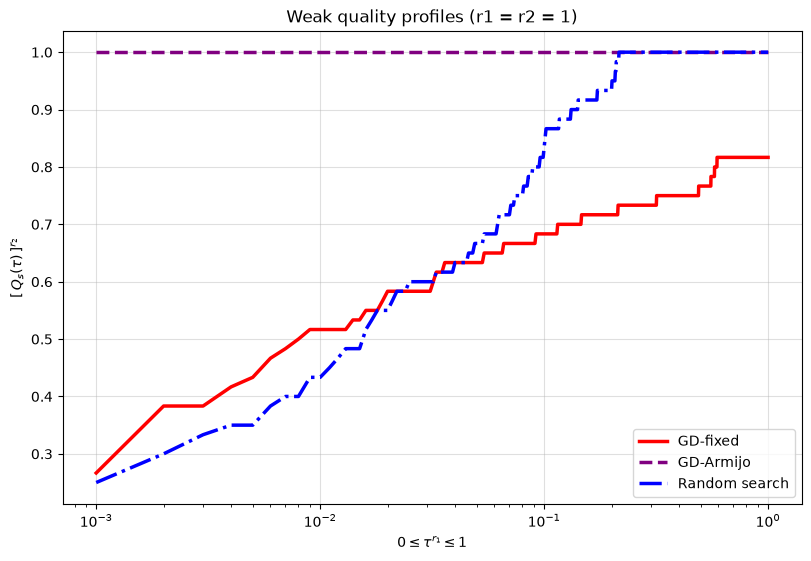

In [4]:
qp = quality_profiles(f0, f_solvers, solver_names=names)
plot_quality_profiles(qp, title="Weak quality profiles (r1 = r2 = 1)")
plt.show()

How to read the plot:

* at the left end ($\tau \to 0$), the value is the fraction of problems on which the solver found the **best** value among all solvers;
* at $\tau = 1$, the value is the fraction of problems on which the solver did not fail and did not end above $f(x_0)$;
* the higher the curve, the better.

## 3. Zoom with `r1` and `r2`

The profiles are plotted against $\tau^{r_1}$ and their values are raised to $r_2$. With $r_1 = 1$ the grid only reaches $\tau = 10^{-3}$. Larger values of `r1` push the samples towards $0$, i.e. towards **high accuracy**. `r2` stretches the ordinate. The ranking among solvers does not depend on `r1` or `r2`.

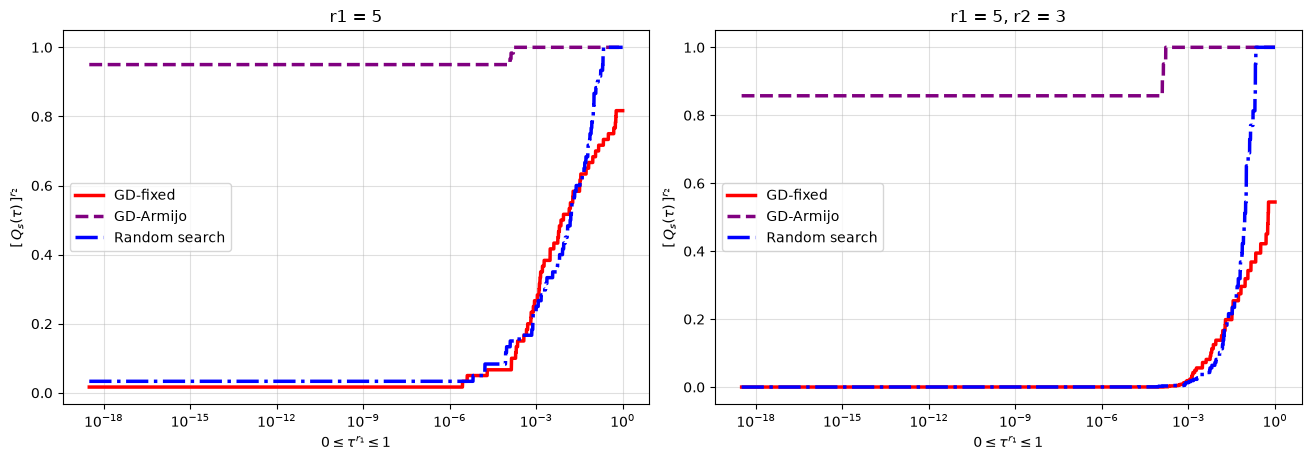

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
plot_quality_profiles(
    quality_profiles(f0, f_solvers, solver_names=names, r1=5), axes[0], title="r1 = 5"
)
plot_quality_profiles(
    quality_profiles(f0, f_solvers, solver_names=names, r1=5, r2=3), axes[1], title="r1 = 5, r2 = 3"
)
plt.show()

## 4. Numbers instead of pictures

`evaluate` computes the profiles exactly at any precision level. At $\tau = 10^{-k}$ it gives the fraction of problems on which each solver reduced $f(x_0) - f_L$ by at least $k$ orders of magnitude.

In [6]:
levels = [1e-1, 1e-2, 1e-4, 1e-8, 0.0]
table = qp.evaluate(levels)
print(f"{'tau':>8}  " + "  ".join(f"{n:>13}" for n in qp.solver_names))
for lv, row in zip(levels, table, strict=True):
    print(f"{lv:>8.0e}  " + "  ".join(f"{v:>13.2f}" for v in row))

     tau       GD-fixed      GD-Armijo  Random search
   1e-01           0.68           1.00           0.83
   1e-02           0.52           1.00           0.43
   1e-04           0.07           0.95           0.13
   1e-08           0.02           0.95           0.03
   0e+00           0.02           0.95           0.03


The area under each curve gives one number per solver (larger is better), which can be used to rank the solvers. With `r1 > 1` the area puts more weight on high-accuracy levels.

In [7]:
for r1 in (1, 5):
    ranking = quality_profiles(f0, f_solvers, solver_names=names, r1=r1).ranking()
    print(f"r1 = {r1}:", ", ".join(f"{name} ({area:.3f})" for name, area in ranking))

r1 = 1: GD-Armijo (1.000), Random search (0.954), GD-fixed (0.759)
r1 = 5: GD-Armijo (0.992), Random search (0.579), GD-fixed (0.502)


## 5. Strong profiles and a custom reference value

* `strong=True` replaces $f(x_0)$ with the **worst** value found by the solvers, which makes the comparison more discriminating when the solvers end up close to each other.
* `f_ref` lets you pass your own reference values $f_L^{(p)}$, for instance known optimal values. Each solver's profile then no longer depends on which other solvers are in the comparison. Here every test function has minimum value $0$.

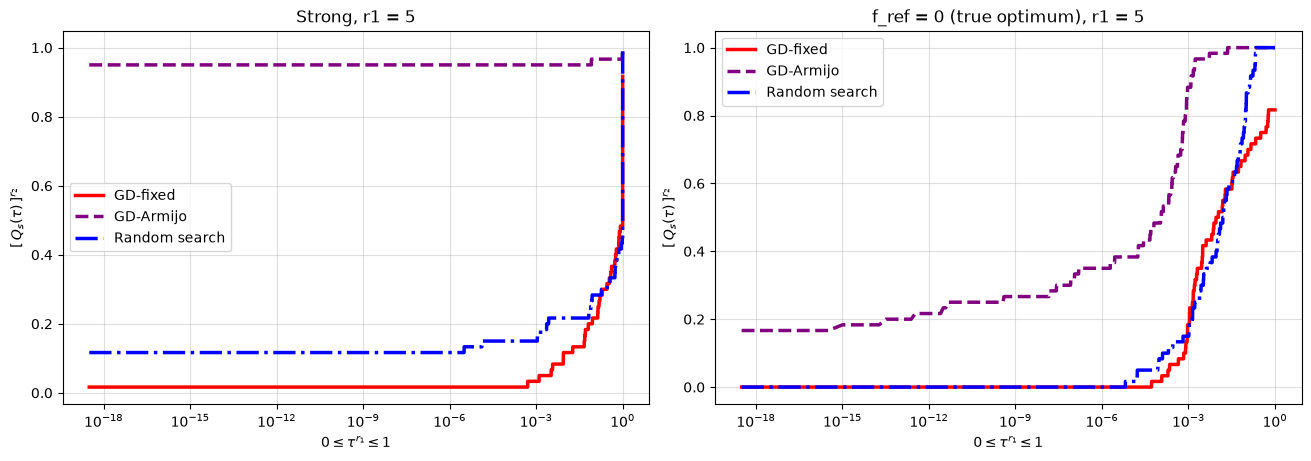

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
plot_quality_profiles(
    quality_profiles(f0, f_solvers, solver_names=names, r1=5, strong=True),
    axes[0],
    title="Strong, r1 = 5",
)
plot_quality_profiles(
    quality_profiles(f0, f_solvers, solver_names=names, r1=5, f_ref=np.zeros_like(f0)),
    axes[1],
    title="f_ref = 0 (true optimum), r1 = 5",
)
plt.show()

## 6. Results stored as a matrix

If your results are stored like the `TT` matrix of the reference MATLAB code (first column $f(x_0)$, then one column per solver), use `split_matrix`. The `examples/data` folder holds the results used in the paper in this layout, and `examples/reproduce_paper_figures.py` redraws the paper's figures from them.

In [9]:
from quality_profiles import split_matrix

tt = np.column_stack([f0, f_solvers])
f0_, fs_ = split_matrix(tt)
np.testing.assert_array_equal(quality_profiles(f0_, fs_).values, qp.values)